# Question 2 — Sections 2 and 3

23K-0073 | Kaggle T4

## Setup

In [1]:
import os, subprocess, sys
os.environ['CUDA_VISIBLE_DEVICES'] = '0'
subprocess.run([sys.executable, '-m', 'pip', 'uninstall', '-y', 'torchao'], check=True, capture_output=True)
packages = [
    'transformers>=4.51,<5', 'peft>=0.15,<0.20', 'accelerate>=1.0,<2',
    'datasets>=3.0,<5', 'bitsandbytes>=0.45,<0.50', 'huggingface_hub>=0.30',
    'numpy', 'pandas', 'matplotlib', 'safetensors'
]
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *packages])
print('Dependencies ready')

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.30.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.30.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
diffusers 0.42.0 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


Dependencies ready


In [2]:
import os, sys, gc, time, math, json, hashlib, random, platform, zipfile
from pathlib import Path
from datetime import datetime, timezone
from collections import Counter
from importlib import metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import transformers, peft, datasets, bitsandbytes
from datasets import load_dataset
from transformers import (AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig,
                          Trainer, TrainingArguments, TrainerCallback, set_seed)
from transformers.trainer_utils import get_last_checkpoint
from peft import LoraConfig, AdaLoraConfig, TaskType, get_peft_model, PeftModel, prepare_model_for_kbit_training
from IPython.display import display

assert torch.cuda.is_available(), "CUDA GPU is required. In Kaggle select Settings > Accelerator > GPU T4 x2."
print("GPU:", torch.cuda.get_device_name(0), "| using CUDA device 0 only")
print("VRAM GB:", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2))
print("torch:", torch.__version__, "transformers:", transformers.__version__, "peft:", peft.__version__)


I0000 00:00:1794722214.344963      23 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


GPU: Tesla T4 | using CUDA device 0 only
VRAM GB: 15.64
torch: 2.11.0+cu130 transformers: 4.57.6 peft: 0.19.1


## Output folder

In [3]:
ROOT = Path('/kaggle/working/Assignment_Beta_Q2_23K-0073')
for sub in ('data', 'adapters', 'checkpoints', 'runs', 'predictions', 'figures', 'exports'):
    (ROOT / sub).mkdir(parents=True, exist_ok=True)
print('Results:', ROOT)

Results: /kaggle/working/Assignment_Beta_Q2_23K-0073


## Settings

In [4]:
CFG = {
    'student_id': '23K-0073',
    'model': 'Qwen/Qwen2.5-1.5B-Instruct',
    'dataset': 'korotkov/glaive-function-calling-v2-parsed',
    'dataset_split': 'train',
    'seed': 73,
    'n_total': 2000,
    'n_function_call': 1700,
    'n_no_call': 300,
    'n_train': 1600, 'n_validation': 200, 'n_test': 200,
    'max_sequence_tokens': 640,
    'max_prompt_tokens': 535,
    'max_target_tokens': 100,
    'generation_max_new_tokens': 128,
    'epochs': 2,
    'microbatch': 1,
    'grad_accum': 8,
    'learning_rate': 2e-4,
    'warmup_ratio': 0.05,
    'weight_decay': 0.0,
    'lora_alpha': 16,
    'dropout': 0.05,
    'target_modules': ['q_proj', 'k_proj', 'v_proj', 'o_proj'],
    'generation_batch': 4,
}
PROTOCOL_HASH = hashlib.sha256(json.dumps(CFG, sort_keys=True).encode()).hexdigest()[:16]
lock_file = ROOT / 'protocol_lock.json'
if lock_file.exists():
    previous = json.loads(lock_file.read_text())
    assert previous['sha256_prefix'] == PROTOCOL_HASH, (
        'Existing results used another configuration. Restore the previous CFG or use a new project folder.')
else:
    lock_file.write_text(json.dumps({'sha256_prefix': PROTOCOL_HASH, 'config': CFG}, indent=2))
SEED = CFG['seed']
set_seed(SEED)
DTYPE = torch.bfloat16 if torch.cuda.is_bf16_supported(including_emulation=False) else torch.float16
print('Protocol:', PROTOCOL_HASH, '| precision:', DTYPE)


Protocol: ff47a42700f8fe7f | precision: torch.float16


## Dataset

In [5]:
tokenizer = AutoTokenizer.from_pretrained(CFG['model'], use_fast=True)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = 'right'

ROUTER_RULES = (
    'You are a function-call router. Your only output is exactly one valid JSON object with keys '
    '"name" and "arguments". Choose an available function only if the user has provided '
    'enough information and requested that action. Never invent a function or a parameter. '
    'If no listed function should be called, output {"name":"none","arguments":{}}. '
    'Do not include Markdown, prose, code fences or explanations.'
)

def normalize_tool_definition(obj):
    if not isinstance(obj, dict):
        return None
    item = obj.get('function', obj)
    if not isinstance(item, dict) or not isinstance(item.get('name'), str):
        return None
    return {k: item[k] for k in ('name','description','parameters') if k in item}

def make_prompt(tools, request):
    tool_text = json.dumps(tools, ensure_ascii=False, separators=(',', ':'))
    messages = [
        {'role':'system', 'content':ROUTER_RULES + '\nAvailable functions: ' + tool_text},
        {'role':'user', 'content':request}
    ]
    return tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)

def standardize_glaive(raw, shuffled_position):
    try:
        messages = json.loads(raw['messages'])
        tool_list = json.loads(raw['functions'])
        if not isinstance(messages, list) or not isinstance(tool_list, list):
            return None
        tools = [normalize_tool_definition(t) for t in tool_list]
        tools = [t for t in tools if t is not None]
        if not tools or len(tools) > 3:
            return None
        names = [t['name'] for t in tools]
        if len(names) != len(set(names)) or 'none' in names:
            return None
        pos = next(i for i,m in enumerate(messages) if m.get('role')=='user' and isinstance(m.get('content'),str))
        if pos+1 >= len(messages):
            return None
        request = messages[pos]['content'].strip()
        next_msg = messages[pos+1]
        if not request or len(request)>800 or next_msg.get('role') not in ('function_call','assistant'):
            return None
        if next_msg['role'] == 'function_call':
            action = json.loads(next_msg['content'])
            if not isinstance(action, dict) or action.get('name') not in names:
                return None
            args = action.get('arguments', {})
            if isinstance(args, str):
                args = json.loads(args)
            if not isinstance(args, dict):
                return None
            category = 'call'
            target = {'name': action['name'], 'arguments': args}
        else:
            if any(m.get('role')=='function_call' for m in messages):
                return None
            category = 'no_call'
            target = {'name': 'none', 'arguments': {}}
        gold = json.dumps(target, ensure_ascii=False, sort_keys=True, separators=(',',':'))
        prompt = make_prompt(tools, request)
        prompt_len = len(tokenizer(prompt, add_special_tokens=False)['input_ids'])
        gold_len = len(tokenizer(gold, add_special_tokens=False)['input_ids']) + 1
        if prompt_len > CFG['max_prompt_tokens'] or gold_len > CFG['max_target_tokens']:
            return None
        if prompt_len + gold_len > CFG['max_sequence_tokens']:
            return None
        digest = hashlib.sha256((prompt+'\n'+gold).encode()).hexdigest()
        return {'id':digest[:16], 'source_shuffle_position':shuffled_position,
                'category':category, 'user':request, 'tools':tools,
                'prompt':prompt, 'gold':gold, 'prompt_len':prompt_len, 'target_len':gold_len}
    except (ValueError, TypeError, KeyError, IndexError, StopIteration, AttributeError):
        return None

fake = {'functions':json.dumps([{'name':'track_shipment','parameters':{'type':'object','properties':{'id':{'type':'string'}}}}]),
        'messages':json.dumps([{'role':'user','content':'Track shipment SH-42'},
                               {'role':'function_call','content':json.dumps({'name':'track_shipment','arguments':{'id':'SH-42'}})}])}
assert json.loads(standardize_glaive(fake,0)['gold'])['name'] == 'track_shipment'
fake_no = dict(fake, messages=json.dumps([{'role':'user','content':'Hello'},
                                         {'role':'assistant','content':'Hi'}]))
assert json.loads(standardize_glaive(fake_no,1)['gold'])['name'] == 'none'
print('Schema parser passed synthetic unit tests.')


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Schema parser passed synthetic unit tests.


In [6]:
def write_jsonl(path, rows):
    path = Path(path)
    with path.open('w', encoding='utf-8') as f:
        for r in rows:
            f.write(json.dumps(r, ensure_ascii=False, sort_keys=True)+'\n')

def read_jsonl(path):
    with Path(path).open(encoding='utf-8') as f:
        return [json.loads(line) for line in f if line.strip()]

def dataset_hash(*groups):
    return hashlib.sha256('\n'.join(ex['id'] for group in groups for ex in group).encode()).hexdigest()

paths = {split: ROOT/'data'/f'{split}.jsonl' for split in ('train','validation','test')}
manifest_file = ROOT/'data'/'dataset_manifest.json'
if manifest_file.exists():
    data_manifest = json.loads(manifest_file.read_text())
    assert data_manifest['protocol_hash'] == PROTOCOL_HASH, 'Dataset manifest does not match frozen protocol.'
    partitions = {name:read_jsonl(path) for name,path in paths.items()}
    assert dataset_hash(*(partitions[s] for s in ('train','validation','test'))) == data_manifest['data_sha256']
    print('Loaded existing, validated split from Drive.')
else:
    raw = load_dataset(CFG['dataset'], split=CFG['dataset_split'])
    raw = raw.shuffle(seed=SEED)
    buckets = {'call':[], 'no_call':[]}
    selected_hashes = set()
    scanned = 0
    for i, rec in enumerate(raw):
        scanned += 1
        item = standardize_glaive(rec, i)
        if item is None or item['id'] in selected_hashes:
            continue
        kind = item['category']
        cap = CFG['n_function_call'] if kind=='call' else CFG['n_no_call']
        if len(buckets[kind]) < cap:
            buckets[kind].append(item)
            selected_hashes.add(item['id'])
        if len(buckets['call'])==CFG['n_function_call'] and len(buckets['no_call'])==CFG['n_no_call']:
            break
    assert len(buckets['call']) == 1700 and len(buckets['no_call']) == 300, (
        f'Not enough eligible records; scanned={scanned}, counts={ {k:len(v) for k,v in buckets.items()} }. '
        'Investigate parser and dataset schema before changing the frozen protocol.')
    rng = random.Random(SEED)
    for v in buckets.values():
        rng.shuffle(v)

    partitions = {
        'test': buckets['call'][:170] + buckets['no_call'][:30],
        'validation': buckets['call'][170:340] + buckets['no_call'][30:60],
        'train': buckets['call'][340:] + buckets['no_call'][60:]
    }
    for group in partitions.values():
        rng.shuffle(group)
    assert [len(partitions[s]) for s in ('train','validation','test')] == [1600,200,200]
    assert len(set(ex['id'] for group in partitions.values() for ex in group)) == 2000
    for name,path in paths.items():
        write_jsonl(path,partitions[name])
    data_manifest = {'source':CFG['dataset'], 'source_partition':'train', 'seed':SEED,
                     'protocol_hash':PROTOCOL_HASH, 'n_source_rows_scanned':scanned,
                     'split_sizes':{s:len(v) for s,v in partitions.items()},
                     'class_counts':{s:dict(Counter(ex['category'] for ex in v)) for s,v in partitions.items()},
                     'data_sha256':dataset_hash(*(partitions[s] for s in ('train','validation','test'))),
                     'selection_policy':'first-user next-action; no truncation; deduplicated; 85/15 stratified'}
    manifest_file.write_text(json.dumps(data_manifest,indent=2))
    del raw
    gc.collect()
print(json.dumps(data_manifest,indent=2))
print('Train/validation/test:', *[len(partitions[s]) for s in ('train','validation','test')])
print('Test examples are sealed until the final evaluation stage.')


README.md: 0.00B [00:00, ?B/s]

glaive-function-calling-v2-parsed-train.(…):   0%|          | 0.00/304M [00:00<?, ?B/s]

glaive-function-calling-v2-parsed-test.j(…):   0%|          | 0.00/37.7M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/100199 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/12553 [00:00<?, ? examples/s]

{
  "source": "korotkov/glaive-function-calling-v2-parsed",
  "source_partition": "train",
  "seed": 73,
  "protocol_hash": "ff47a42700f8fe7f",
  "n_source_rows_scanned": 6932,
  "split_sizes": {
    "test": 200,
    "validation": 200,
    "train": 1600
  },
  "class_counts": {
    "test": {
      "call": 170,
      "no_call": 30
    },
    "validation": {
      "no_call": 30,
      "call": 170
    },
    "train": {
      "call": 1360,
      "no_call": 240
    }
  },
  "data_sha256": "c66c50c9cb3e54d5d09a1c838584be4fa7b1560790c2eec3b05438d831d1b683",
  "selection_policy": "first-user next-action; no truncation; deduplicated; 85/15 stratified"
}
Train/validation/test: 1600 200 200
Test examples are sealed until the final evaluation stage.


## Tokenization

In [7]:
class CompletionExamples(torch.utils.data.Dataset):
    def __init__(self, examples):
        self.rows = []
        for ex in examples:
            p = tokenizer(ex['prompt'], add_special_tokens=False)['input_ids']
            t = tokenizer(ex['gold'], add_special_tokens=False)['input_ids'] + [tokenizer.eos_token_id]
            assert len(p)+len(t) <= CFG['max_sequence_tokens']
            self.rows.append({'input_ids':p+t, 'labels':[-100]*len(p)+t})
    def __len__(self):
        return len(self.rows)
    def __getitem__(self,idx):
        return self.rows[idx]

class CompletionPadder:
    def __call__(self, rows):
        max_len = max(len(row['input_ids']) for row in rows)
        input_ids, labels, masks = [], [], []
        for row in rows:
            delta = max_len-len(row['input_ids'])
            input_ids.append(row['input_ids']+[tokenizer.pad_token_id]*delta)
            labels.append(row['labels']+[-100]*delta)
            masks.append([1]*len(row['input_ids'])+[0]*delta)
        return {'input_ids':torch.tensor(input_ids,dtype=torch.long),
                'attention_mask':torch.tensor(masks,dtype=torch.long),
                'labels':torch.tensor(labels,dtype=torch.long)}

train_data = CompletionExamples(partitions['train'])
collator = CompletionPadder()
first = collator([train_data[0],train_data[1]])
assert first['labels'].eq(-100).sum().item() > 0
assert first['input_ids'].shape == first['labels'].shape
print('Tokenized train size:',len(train_data),'| example batch tensor:',tuple(first['input_ids'].shape))


Tokenized train size: 1600 | example batch tensor: (2, 280)


## Adapters

In [8]:
def release_gpu(*objects):
    for o in objects:
        del o
    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.ipc_collect()

def load_base_model(quantized=False):
    params = {'device_map':{'':0}, 'dtype':DTYPE, 'low_cpu_mem_usage':True}
    if quantized:
        params['quantization_config'] = BitsAndBytesConfig(
            load_in_4bit=True, bnb_4bit_quant_type='nf4',
            bnb_4bit_use_double_quant=True, bnb_4bit_compute_dtype=DTYPE)
    return AutoModelForCausalLM.from_pretrained(CFG['model'], **params)

base_count_file = ROOT/'data'/'base_count.json'
if base_count_file.exists():
    BASE_PARAM_COUNT = json.loads(base_count_file.read_text())['parameter_count']
else:
    tmp = load_base_model()
    BASE_PARAM_COUNT = sum(p.numel() for p in tmp.parameters())
    base_count_file.write_text(json.dumps({'model':CFG['model'],'parameter_count':BASE_PARAM_COUNT},indent=2))
    del tmp
    release_gpu()
print('Nominal base parameters:',format(BASE_PARAM_COUNT,','))

def adalora_initial_rank(target_rank):
    return target_rank + 4

def build_adapter(method, target_rank, total_optimizer_steps):
    assert method in ('lora','qlora','dora','adalora')
    set_seed(SEED)
    model = load_base_model(quantized=(method=='qlora'))
    if method == 'qlora':
        model = prepare_model_for_kbit_training(model, use_gradient_checkpointing=True)
    model.config.use_cache = False
    shared = dict(task_type=TaskType.CAUSAL_LM,
                  target_modules=CFG['target_modules'],
                  lora_alpha=CFG['lora_alpha'],
                  lora_dropout=CFG['dropout'], bias='none')
    if method == 'adalora':
        conf = AdaLoraConfig(r=target_rank,
                            init_r=adalora_initial_rank(target_rank),
                            target_r=target_rank,
                            tinit=max(1,round(total_optimizer_steps*0.10)),
                            tfinal=max(1,round(total_optimizer_steps*0.10)),
                            deltaT=max(1,round(total_optimizer_steps*0.025)),
                            total_step=total_optimizer_steps,
                            orth_reg_weight=0.5, **shared)
    else:
        conf = LoraConfig(r=target_rank, use_dora=(method=='dora'), **shared)
    model = get_peft_model(model,conf)
    model.enable_input_require_grads()
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return model, int(trainable), conf

class AllocateAdaRank(TrainerCallback):
    def __init__(self, model):
        self.model = model
    def on_optimizer_step(self,args,state,control,**kwargs):

        self.model.base_model.update_and_allocate(state.global_step+1)
        return control

STEPS_PER_EPOCH = math.ceil(len(train_data)/(CFG['microbatch']*CFG['grad_accum']))
TOTAL_STEPS = int(STEPS_PER_EPOCH*CFG['epochs'])
print('Effective batch size:',CFG['microbatch']*CFG['grad_accum'],
      '| Optimizer steps per run:',TOTAL_STEPS)


config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/3.09G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Nominal base parameters: 1,543,714,304
Effective batch size: 8 | Optimizer steps per run: 400


## Metrics

In [9]:
def inspect_prediction(generated, gold_string, authorized):
    gold = json.loads(gold_string)
    parsed = None
    try:
        parsed = json.loads(generated.strip())
        json_valid = True
    except (json.JSONDecodeError, ValueError, TypeError):
        json_valid = False
    schema_valid = (isinstance(parsed,dict) and set(parsed)=={'name','arguments'} and
                    isinstance(parsed.get('name'),str) and isinstance(parsed.get('arguments'),dict))
    allowed_name = parsed.get('name') in (set(authorized)|{'none'}) if schema_valid else False
    tool_correct = bool(schema_valid and allowed_name and parsed['name']==gold['name'])
    full_match = bool(tool_correct and parsed['arguments']==gold['arguments'])
    if not json_valid:
        error='broken_json'
    elif not schema_valid:
        error='invalid_schema'
    elif not allowed_name:
        error='unauthorized_or_invented_tool'
    elif gold['name']=='none' and parsed['name']!='none':
        error='unnecessary_action'
    elif gold['name']!='none' and parsed['name']=='none':
        error='missed_tool'
    elif not tool_correct:
        error='wrong_tool'
    elif not full_match:
        error='wrong_arguments'
    else:
        error='correct'
    return {'json_valid':json_valid, 'schema_valid':schema_valid,
            'tool_correct':tool_correct, 'full_match':full_match, 'error_category':error}

valid_good = inspect_prediction('{"name":"track_shipment","arguments":{"id":"T1"}}',
    '{"name":"track_shipment","arguments":{"id":"T1"}}', ['track_shipment'])
assert valid_good['json_valid'] and valid_good['full_match']
assert not inspect_prediction('Here: {"name":"none","arguments":{}}', '{"name":"none","arguments":{}}',[])['json_valid']
assert inspect_prediction('{"name":"initiate_refund","arguments":{}}','{"name":"none","arguments":{}}',['initiate_refund'])['error_category']=='unnecessary_action'
print('Metric unit tests passed.')

@torch.inference_mode()
def run_predictions(model, examples, stage, run_id):
    model.eval()
    model.config.use_cache = True
    tokenizer.padding_side = 'left'
    begun = time.perf_counter()
    rows=[]
    bs=CFG['generation_batch']
    for offset in range(0,len(examples),bs):
        subset = examples[offset:offset+bs]
        prompts = [e['prompt'] for e in subset]
        encoded = tokenizer(prompts, return_tensors='pt', padding=True, truncation=False,
                            add_special_tokens=False).to('cuda')
        generated = model.generate(**encoded, do_sample=False, num_beams=1,
                                   max_new_tokens=CFG['generation_max_new_tokens'],
                                   pad_token_id=tokenizer.pad_token_id,
                                   eos_token_id=tokenizer.eos_token_id)
        completions = generated[:, encoded['input_ids'].shape[1]:]
        decoded = tokenizer.batch_decode(completions,skip_special_tokens=True)
        for example, output in zip(subset, decoded):
            gold=json.loads(example['gold'])
            record={'id':example['id'], 'run_id':run_id,'stage':stage,
                    'user':example['user'],'available_tools':[t['name'] for t in example['tools']],
                    'gold_name':gold['name'], 'gold':example['gold'], 'raw_output':output,
                    'category':example['category']}
            record.update(inspect_prediction(output,example['gold'],record['available_tools']))
            rows.append(record)
        if (offset+bs)%40==0 or offset+bs>=len(examples):
            print(f'  {stage} {run_id}: {min(offset+bs,len(examples))}/{len(examples)} predictions')
        del encoded, generated, completions
    elapsed=time.perf_counter()-begun
    summary={'n':len(rows), 'json_valid_count':sum(r['json_valid'] for r in rows),
             'schema_valid_count':sum(r['schema_valid'] for r in rows),
             'tool_correct_count':sum(r['tool_correct'] for r in rows),
             'full_match_count':sum(r['full_match'] for r in rows),
             'json_valid_pct':100*np.mean([r['json_valid'] for r in rows]),
             'schema_valid_pct':100*np.mean([r['schema_valid'] for r in rows]),
             'tool_accuracy_pct':100*np.mean([r['tool_correct'] for r in rows]),
             'full_match_pct':100*np.mean([r['full_match'] for r in rows]),
             'inference_seconds':round(elapsed,3)}
    tokenizer.padding_side = 'right'
    return rows, summary


Metric unit tests passed.


## Training

In [10]:
def key_for(method,rank):
    return f'{method}_r{rank}' if method!='base' else 'baseline'

def train_one(method,rank):
    assert method!='base'
    run_id = key_for(method,rank)
    saved_stats = ROOT/'runs'/f'{run_id}_training.json'
    adapter_dir = ROOT/'adapters'/run_id
    if saved_stats.exists() and (adapter_dir/'adapter_config.json').exists():
        obj=json.loads(saved_stats.read_text())
        assert obj['protocol_hash']==PROTOCOL_HASH and obj['data_sha256']==data_manifest['data_sha256']
        assert obj['train_complete'] is True
        print('Reuse verified completed training:',run_id)
        return obj
    ckpt_dir = ROOT/'checkpoints'/run_id
    ckpt_dir.mkdir(parents=True,exist_ok=True)
    model,trainable,config = build_adapter(method,rank,TOTAL_STEPS)
    model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={'use_reentrant':False})
    callbacks=[AllocateAdaRank(model)] if method=='adalora' else []
    args=TrainingArguments(
        output_dir=str(ckpt_dir),
        per_device_train_batch_size=CFG['microbatch'],
        gradient_accumulation_steps=CFG['grad_accum'],
        num_train_epochs=CFG['epochs'],
        learning_rate=CFG['learning_rate'],
        lr_scheduler_type='linear', warmup_ratio=CFG['warmup_ratio'],
        weight_decay=CFG['weight_decay'],
        optim='paged_adamw_32bit',
        fp16=(DTYPE==torch.float16),bf16=(DTYPE==torch.bfloat16),
        gradient_checkpointing=True,
        gradient_checkpointing_kwargs={'use_reentrant':False},
        eval_strategy='no', save_strategy='steps',
        save_steps=max(25,TOTAL_STEPS//4),save_total_limit=2,
        logging_strategy='steps',logging_steps=25,
        report_to='none', remove_unused_columns=False,
        seed=SEED,data_seed=SEED,dataloader_num_workers=0,
        group_by_length=False,
    )
    trainer=Trainer(model=model,args=args,train_dataset=train_data,
                    data_collator=collator,callbacks=callbacks)
    last_checkpoint=get_last_checkpoint(str(ckpt_dir))
    if last_checkpoint:
        print('Resume checkpoint:',last_checkpoint)
    torch.cuda.reset_peak_memory_stats(0)
    t0=time.perf_counter()
    train_result=trainer.train(resume_from_checkpoint=last_checkpoint)
    duration=time.perf_counter()-t0
    peak_allocated=torch.cuda.max_memory_allocated(0)
    adapter_dir.mkdir(parents=True,exist_ok=True)
    model.save_pretrained(str(adapter_dir),safe_serialization=True)
    stats={'run_id':run_id,'method':method,'rank':rank,
           'ada_init_rank':adalora_initial_rank(rank) if method=='adalora' else None,
           'protocol_hash':PROTOCOL_HASH,'data_sha256':data_manifest['data_sha256'],
           'base_parameters':BASE_PARAM_COUNT,'trainable_parameters':trainable,
           'trainable_pct_whole':100*trainable/(BASE_PARAM_COUNT+trainable),
           'peak_train_memory_gib':peak_allocated/(1024**3),
           'training_minutes':duration/60,'train_loss':float(train_result.training_loss),
           'trained_steps':int(trainer.state.global_step),
           'train_complete':True,'trained_at_utc':datetime.now(timezone.utc).isoformat(),
           'adapter_folder':str(adapter_dir),'precision':'NF4 + '+str(DTYPE) if method=='qlora' else str(DTYPE)}
    saved_stats.write_text(json.dumps(stats,indent=2))
    print(f"Saved {run_id}: {duration/60:.1f} min, {peak_allocated/1024**3:.2f} GiB peak")
    del trainer,model,train_result
    gc.collect();torch.cuda.empty_cache()
    return stats

def load_for_inference(method,rank):
    base=load_base_model(quantized=(method=='qlora'))
    if method=='base':
        model=base
    else:
        folder=ROOT/'adapters'/key_for(method,rank)
        assert (folder/'adapter_config.json').exists(),f'Missing completed adapter: {folder}'
        model=PeftModel.from_pretrained(base,str(folder),is_trainable=False)
    model.eval();model.config.use_cache=True
    return model

def evaluate_run(method,rank,split_name):
    run_id=key_for(method,rank)
    assert split_name in ('validation','test')
    out=ROOT/'predictions'/f'{split_name}_{run_id}.jsonl'
    metrics_path=ROOT/'runs'/f'{split_name}_{run_id}_metrics.json'
    if out.exists() and metrics_path.exists():
        report=json.loads(metrics_path.read_text())
        assert report['protocol_hash']==PROTOCOL_HASH and report['data_sha256']==data_manifest['data_sha256']
        assert len(read_jsonl(out))==len(partitions[split_name])
        print('Reuse completed',split_name,'predictions for',run_id)
        return report
    model=load_for_inference(method,rank)
    if split_name=='test':
        assert (ROOT/'runs'/'selection_frozen.json').exists(), 'Freeze method/rank selection before running test.'
    torch.cuda.reset_peak_memory_stats(0)
    predictions,metrics=run_predictions(model,partitions[split_name],split_name,run_id)
    metrics.update({'run_id':run_id,'method':method,'rank':rank,'split':split_name,
                    'protocol_hash':PROTOCOL_HASH,'data_sha256':data_manifest['data_sha256'],
                    'peak_inference_memory_gib':torch.cuda.max_memory_allocated(0)/1024**3,
                    'timestamp_utc':datetime.now(timezone.utc).isoformat()})
    write_jsonl(out,predictions)
    metrics_path.write_text(json.dumps(metrics,indent=2))
    del model,predictions
    gc.collect();torch.cuda.empty_cache()
    return metrics


In [11]:
from IPython.display import FileLink

def save_progress():
    target = Path('/kaggle/working/Q2_PROGRESS_LATEST_23K-0073.zip')
    with zipfile.ZipFile(target, 'w', compression=zipfile.ZIP_DEFLATED) as z:
        for f in [ROOT / 'protocol_lock.json']:
            if f.exists():
                z.write(f, arcname=str(f.relative_to(ROOT)))
        for folder in ('data', 'adapters', 'runs', 'predictions', 'exports', 'figures'):
            for f in sorted((ROOT / folder).rglob('*')):
                if f.is_file():
                    z.write(f, arcname=str(f.relative_to(ROOT)))
    print('Progress saved:', target, '| MB:', round(target.stat().st_size / 1e6, 1))
    display(FileLink(str(target)))


## Section 2 — Methods

In [12]:
validation_results=[]
validation_results.append(evaluate_run('base',0,'validation'))
save_progress()
for method in ['lora','qlora','dora','adalora']:
    train_one(method,8)
    validation_results.append(evaluate_run(method,8,'validation'))
    save_progress()
val_table=pd.DataFrame(validation_results)
display(val_table[['run_id','n','json_valid_count','tool_correct_count','full_match_count',
                   'json_valid_pct','tool_accuracy_pct','full_match_pct','inference_seconds']])
val_table.to_csv(ROOT/'exports'/'validation_comparison.csv',index=False)
print('Validation results saved. Held-out test remains untouched.')


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


  validation baseline: 40/200 predictions
  validation baseline: 80/200 predictions
  validation baseline: 120/200 predictions
  validation baseline: 160/200 predictions
  validation baseline: 200/200 predictions
Progress saved: /kaggle/working/Q2_PROGRESS_LATEST_23K-0073.zip | MB: 0.4


/kaggle/working/Q2_PROGRESS_LATEST_23K-0073.zip

The model is already on multiple devices. Skipping the move to device specified in `args`.


Step,Training Loss
25,0.613200
50,0.039700
75,0.024500
100,0.021100
125,0.012000
150,0.020500
175,0.018700
200,0.017100
225,0.005500
250,0.008800


Saved lora_r8: 18.8 min, 3.79 GiB peak
  validation lora_r8: 40/200 predictions
  validation lora_r8: 80/200 predictions
  validation lora_r8: 120/200 predictions
  validation lora_r8: 160/200 predictions
  validation lora_r8: 200/200 predictions
Progress saved: /kaggle/working/Q2_PROGRESS_LATEST_23K-0073.zip | MB: 8.4


... (13 outputs left out)

Saved adalora_r8: 26.5 min, 3.84 GiB peak
  validation adalora_r8: 40/200 predictions
  validation adalora_r8: 80/200 predictions
  validation adalora_r8: 120/200 predictions
  validation adalora_r8: 160/200 predictions
  validation adalora_r8: 200/200 predictions
Progress saved: /kaggle/working/Q2_PROGRESS_LATEST_23K-0073.zip | MB: 32.2


/kaggle/working/Q2_PROGRESS_LATEST_23K-0073.zip

,run_id,n,json_valid_count,tool_correct_count,full_match_count,json_valid_pct,tool_accuracy_pct,full_match_pct,inference_seconds
0,baseline,200,198,182,156,99.0,91.0,78.0,76.322
1,lora_r8,200,199,198,188,99.5,99.0,94.0,84.603
2,qlora_r8,200,200,199,191,100.0,99.5,95.5,153.250
3,dora_r8,200,200,199,188,100.0,99.5,94.0,134.443
4,adalora_r8,200,200,198,175,100.0,99.0,87.5,89.031


Validation results saved. Held-out test remains untouched.


## Validation selection

In [13]:
valid_adapters=val_table[val_table['method']!='base'].copy()
valid_adapters=valid_adapters.sort_values(
    ['full_match_pct','tool_accuracy_pct','json_valid_pct','run_id'],
    ascending=[False,False,False,True])
chosen=valid_adapters.iloc[0]
WINNER=str(chosen['method'])
selection_file=ROOT/'runs'/'selection_frozen.json'
selection={'chosen_method':WINNER, 'choice_rule':'validation: full_match then tool_accuracy then JSON validity',
           'winning_r8_validation_full_match_pct':float(chosen['full_match_pct']),
           'winning_r8_validation_tool_accuracy_pct':float(chosen['tool_accuracy_pct']),
           'data_sha256':data_manifest['data_sha256'],'protocol_hash':PROTOCOL_HASH,
           'ranking':valid_adapters[['run_id','full_match_pct','tool_accuracy_pct','json_valid_pct']].to_dict('records')}
if selection_file.exists():
    earlier=json.loads(selection_file.read_text())
    assert earlier['chosen_method']==WINNER and earlier['protocol_hash']==PROTOCOL_HASH
else:
    selection_file.write_text(json.dumps(selection,indent=2))
print('Winner selected without looking at test:',WINNER)
display(valid_adapters[['run_id','full_match_pct','tool_accuracy_pct','json_valid_pct']])


Winner selected without looking at test: qlora


,run_id,full_match_pct,tool_accuracy_pct,json_valid_pct
2,qlora_r8,95.5,99.5,100.0
3,dora_r8,94.0,99.5,100.0
1,lora_r8,94.0,99.0,99.5
4,adalora_r8,87.5,99.0,100.0


## Section 3 — Ranks

In [14]:
rank_validation=[]
for r in [4,16,32]:
    train_one(WINNER,r)
    rank_validation.append(evaluate_run(WINNER,r,'validation'))
    save_progress()
rank_validation.append(evaluate_run(WINNER,8,'validation'))
rank_val=pd.DataFrame(rank_validation).sort_values('rank')
display(rank_val[['run_id','rank','tool_accuracy_pct','full_match_pct','json_valid_pct']])
rank_val.to_csv(ROOT/'exports'/'validation_rank_sweep.csv',index=False)
print('Rank experiments completed. Ready for the first held-out test evaluation.')


/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:213: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


Step,Training Loss
25,0.499800
50,0.041900
75,0.025000
100,0.024400
125,0.013000
150,0.020000
175,0.020800
200,0.015800
225,0.004700
250,0.009700


Saved qlora_r4: 27.9 min, 2.87 GiB peak


/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:213: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


  validation qlora_r4: 40/200 predictions
  validation qlora_r4: 80/200 predictions
  validation qlora_r4: 120/200 predictions
  validation qlora_r4: 160/200 predictions
  validation qlora_r4: 200/200 predictions
Progress saved: /kaggle/working/Q2_PROGRESS_LATEST_23K-0073.zip | MB: 36.3


/kaggle/working/Q2_PROGRESS_LATEST_23K-0073.zip

... (9 outputs left out)

/kaggle/working/Q2_PROGRESS_LATEST_23K-0073.zip

Reuse completed validation predictions for qlora_r8


,run_id,rank,tool_accuracy_pct,full_match_pct,json_valid_pct
0,qlora_r4,4,99.0,94.5,100.0
3,qlora_r8,8,99.5,95.5,100.0
1,qlora_r16,16,99.0,95.0,100.0
2,qlora_r32,32,99.0,95.0,100.0


Rank experiments completed. Ready for the first held-out test evaluation.


## Test evaluation

In [15]:
planned=[('base',0),('lora',8),('qlora',8),('dora',8),('adalora',8)]
planned += [(WINNER,r) for r in (4,16,32)]
assert len(set(planned))==8
assert len(partitions['test'])==200
assert (ROOT/'runs'/'selection_frozen.json').exists()

final_metrics=[]
for method,rank in planned:
    metrics=evaluate_run(method,rank,'test')
    assert metrics['n']==200, 'The assignment requires the entire 200-example held-out test.'
    final_metrics.append(metrics)
    pd.DataFrame(final_metrics).to_csv(ROOT/'exports'/'partial_final_test_metrics.csv',index=False)
final_table=pd.DataFrame(final_metrics)
train_infos={}
for method,rank in planned:
    if method!='base':
        train_infos[key_for(method,rank)]=json.loads((ROOT/'runs'/f'{key_for(method,rank)}_training.json').read_text())
final_table['trainable_parameters']=final_table['run_id'].map(lambda k: train_infos[k]['trainable_parameters'] if k in train_infos else 0)
final_table['trainable_percent']=final_table['run_id'].map(lambda k: train_infos[k]['trainable_pct_whole'] if k in train_infos else 0)
final_table['peak_training_GiB']=final_table['run_id'].map(lambda k: train_infos[k]['peak_train_memory_gib'] if k in train_infos else np.nan)
final_table['training_minutes']=final_table['run_id'].map(lambda k: train_infos[k]['training_minutes'] if k in train_infos else 0.0)
columns=['run_id','method','rank','trainable_parameters','trainable_percent',
         'peak_training_GiB','training_minutes','n','json_valid_count','json_valid_pct',
         'tool_correct_count','tool_accuracy_pct','full_match_count','full_match_pct',
         'inference_seconds','peak_inference_memory_gib']
final_table[columns].to_csv(ROOT/'exports'/'FINAL_ALL_RESULTS.csv',index=False)

method_ids=['baseline']+[key_for(m,8) for m in ('lora','qlora','dora','adalora')]
section2=final_table[final_table['run_id'].isin(method_ids)].copy()
assert len(section2)==5
section2[columns].to_csv(ROOT/'exports'/'SECTION2_FIVE_MODEL_TEST_RESULTS.csv',index=False)
section3=final_table[final_table['method'].eq(WINNER)].sort_values('rank').copy()
assert len(section3)==4 and set(section3['rank'])=={4,8,16,32}
section3[columns].to_csv(ROOT/'exports'/'SECTION3_RANK_TEST_RESULTS.csv',index=False)
display(final_table[columns])


  test baseline: 40/200 predictions
  test baseline: 80/200 predictions
  test baseline: 120/200 predictions
  test baseline: 160/200 predictions
  test baseline: 200/200 predictions
  test lora_r8: 40/200 predictions
  test lora_r8: 80/200 predictions
  test lora_r8: 120/200 predictions
  test lora_r8: 160/200 predictions
  test lora_r8: 200/200 predictions


/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:213: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


  test qlora_r8: 40/200 predictions
  test qlora_r8: 80/200 predictions
  test qlora_r8: 120/200 predictions
  test qlora_r8: 160/200 predictions
  test qlora_r8: 200/200 predictions
  test dora_r8: 40/200 predictions
  test dora_r8: 80/200 predictions
  test dora_r8: 120/200 predictions
  test dora_r8: 160/200 predictions
  test dora_r8: 200/200 predictions
  test adalora_r8: 40/200 predictions
  test adalora_r8: 80/200 predictions
  test adalora_r8: 120/200 predictions
  test adalora_r8: 160/200 predictions
  test adalora_r8: 200/200 predictions
  test qlora_r4: 40/200 predictions
  test qlora_r4: 80/200 predictions
  test qlora_r4: 120/200 predictions
  test qlora_r4: 160/200 predictions
  test qlora_r4: 200/200 predictions
  test qlora_r16: 40/200 predictions
  test qlora_r16: 80/200 predictions
  test qlora_r16: 120/200 predictions
  test qlora_r16: 160/200 predictions
  test qlora_r16: 200/200 predictions
  test qlora_r32: 40/200 predictions
  test qlora_r32: 80/200 predictions
 

,run_id,method,rank,trainable_parameters,trainable_percent,peak_training_GiB,training_minutes,n,json_valid_count,json_valid_pct,tool_correct_count,tool_accuracy_pct,full_match_count,full_match_pct,inference_seconds,peak_inference_memory_gib
0,baseline,base,0,0,0.000000,NaN,0.000000,200,199,99.5,185,92.5,159,79.5,85.063,3.049198
1,lora_r8,lora,8,2179072,0.140959,3.790478,18.843219,200,200,100.0,199,99.5,186,93.0,102.740,3.057315
2,qlora_r8,qlora,8,2179072,0.140959,2.887798,26.985274,200,200,100.0,199,99.5,186,93.0,183.643,1.257202
3,dora_r8,dora,8,2279424,0.147441,3.791605,28.425162,200,200,100.0,199,99.5,185,92.5,162.284,3.057689
4,adalora_r8,adalora,8,3269952,0.211376,3.843248,26.525721,200,199,99.5,195,97.5,163,81.5,107.013,3.056640
5,qlora_r4,qlora,4,1089536,0.070529,2.871562,27.891736,200,200,100.0,199,99.5,186,93.0,182.826,1.253143
6,qlora_r16,qlora,16,4358144,0.281521,2.920269,27.752836,200,200,100.0,199,99.5,185,92.5,183.011,1.265319
7,qlora_r32,qlora,32,8716288,0.561461,2.985210,27.701688,200,200,100.0,199,99.5,185,92.5,183.207,1.281555


## Plots

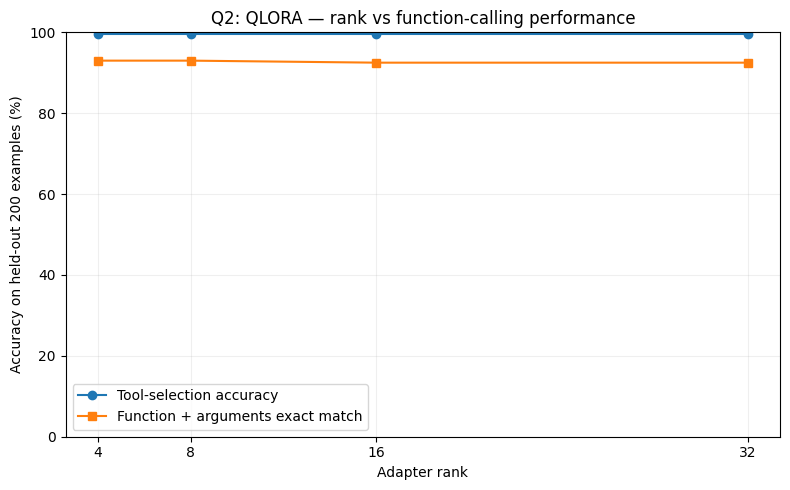

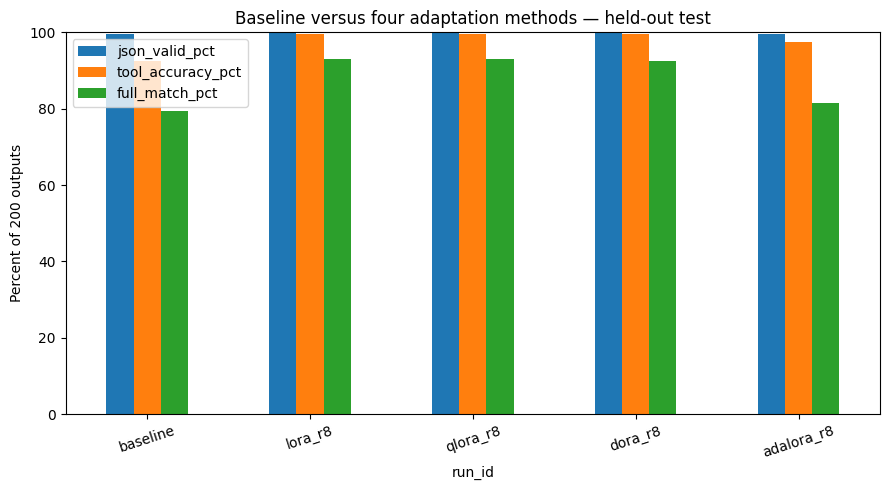

Full-match errors on held-out test: 14
Error types: {'correct': 186, 'unnecessary_action': 1, 'wrong_arguments': 13}

FAILURE 1 | unnecessary_action
Customer: Hi, I have a sentence in French that I need translated to English. The sentence is "Je suis très heureux de vous rencontrer".
Gold: {"arguments":{},"name":"none"}
Predicted: {"arguments":{"source_language":"French","target_language":"English","text":"Je suis très heureux de vous rencontrer"},"name":"translate_text"}

FAILURE 2 | wrong_arguments
Customer: I need images of the Eiffel Tower at night.
Gold: {"arguments":{"query":"Eiffel Tower at night"},"name":"search_images"}
Predicted: {"arguments":{"color":"night","query":"Eiffel Tower"},"name":"search_images"}

FAILURE 3 | wrong_arguments
Customer: Hi, I have a sentence in French that I need translated to English. The sentence is "Je suis très heureux de vous rencontrer".
Gold: {"arguments":{"source_language":"fr","target_language":"en","text":"Je suis très heureux de vous rencon

In [16]:
rank_plot=final_table[(final_table['method']==WINNER)].sort_values('rank')
assert set(rank_plot['rank'])=={4,8,16,32}
plt.figure(figsize=(8,5))
plt.plot(rank_plot['rank'],rank_plot['tool_accuracy_pct'],marker='o',label='Tool-selection accuracy')
plt.plot(rank_plot['rank'],rank_plot['full_match_pct'],marker='s',label='Function + arguments exact match')
plt.xticks([4,8,16,32]);plt.ylim(0,100);plt.xlabel('Adapter rank')
plt.ylabel('Accuracy on held-out 200 examples (%)')
plt.title(f'Q2: {WINNER.upper()} — rank vs function-calling performance')
plt.legend();plt.grid(alpha=0.2);plt.tight_layout()
plt.savefig(ROOT/'figures'/'rank_vs_tool_accuracy.png',dpi=180)
plt.show()

stage2_chart=final_table[final_table['run_id'].isin([key_for(m,8) for m in ['lora','qlora','dora','adalora']]+['baseline'])]
stage2_chart=stage2_chart.set_index('run_id')
stage2_chart[['json_valid_pct','tool_accuracy_pct','full_match_pct']].plot(kind='bar',figsize=(9,5),rot=18)
plt.title('Baseline versus four adaptation methods — held-out test')
plt.ylabel('Percent of 200 outputs');plt.ylim(0,100);plt.tight_layout()
plt.savefig(ROOT/'figures'/'method_comparison.png',dpi=180)
plt.show()

best_id=key_for(WINNER,8)
best_test=read_jsonl(ROOT/'predictions'/f'test_{best_id}.jsonl')
failures=[x for x in best_test if not x['full_match']]
selected_failures=failures[:5]
write_jsonl(ROOT/'exports'/'five_real_failures.jsonl',selected_failures)
error_counts=Counter(x['error_category'] for x in best_test)
(ROOT/'exports'/'error_categories.json').write_text(json.dumps(dict(error_counts),indent=2))
print('Full-match errors on held-out test:',len(failures))
print('Error types:',dict(error_counts))
if len(selected_failures)<5:
    print(f'Only {len(selected_failures)} genuine errors available; do not fabricate additional cases.')
for i,x in enumerate(selected_failures,1):
    print('\nFAILURE',i,'|',x['error_category'])
    print('Customer:',x['user'][:400])
    print('Gold:',x['gold'][:400])
    print('Predicted:',x['raw_output'][:400])


## Export results

In [17]:
package_versions={n:metadata.version(n) for n in
    ['torch','transformers','peft','accelerate','datasets','bitsandbytes','numpy','pandas']}
run_manifest={'student_id':'23K-0073','protocol_hash':PROTOCOL_HASH,
              'config':CFG,'dataset_manifest':data_manifest,
              'winner_method_chosen_using_validation':WINNER,
              'hardware':{'gpu':torch.cuda.get_device_name(0),
                          'total_vram_gib':torch.cuda.get_device_properties(0).total_memory/1024**3,
                          'os':platform.platform()},
              'versions':package_versions,
              'run_ids':list(final_table['run_id']),
              'created_utc':datetime.now(timezone.utc).isoformat(),
              'note':'Results from 200 held-out test examples per run.'}
(ROOT/'exports'/'experiment_manifest.json').write_text(json.dumps(run_manifest,indent=2))

expected=[ROOT/'exports'/'FINAL_ALL_RESULTS.csv',ROOT/'exports'/'validation_comparison.csv',
          ROOT/'exports'/'validation_rank_sweep.csv',ROOT/'exports'/'five_real_failures.jsonl',
          ROOT/'figures'/'rank_vs_tool_accuracy.png',ROOT/'figures'/'method_comparison.png']
assert all(p.exists() for p in expected)
assert len(final_table)==8 and final_table['n'].eq(200).all()

summary=(
    'Assignment Beta Q2 — 23K-0073\n'
    f'Dataset: {CFG["dataset"]} | 1600 train / 200 validation / 200 test\n'
    f'Chosen method from validation: {WINNER}\n'
    f'Base model: {CFG["model"]} | GPU: {torch.cuda.get_device_name(0)}\n'
    'All rows in FINAL_ALL_RESULTS.csv and raw predictions were generated by an executed Kaggle session.\n'
    'Five actual failure examples saved separately.\n'
)
(ROOT/'exports'/'READ_ME_FIRST.txt').write_text(summary)
zip_path=ROOT/'Q2_RESULTS_FOR_REPORT_23K-0073.zip'
with zipfile.ZipFile(zip_path,'w',compression=zipfile.ZIP_DEFLATED) as z:
    for file in [ROOT/'protocol_lock.json',ROOT/'data'/'dataset_manifest.json',
                 ROOT/'data'/'base_count.json',ROOT/'runs'/'selection_frozen.json']:
        z.write(file,arcname=str(file.relative_to(ROOT)))
    for folder in ('runs','predictions','exports','figures'):
        for file in sorted((ROOT/folder).rglob('*')):
            if file.is_file():
                z.write(file,arcname=str(file.relative_to(ROOT)))
print('Results ZIP:',zip_path)
print('ZIP size MB:',round(zip_path.stat().st_size/1e6,2))
print('Saved under /kaggle/working')
from IPython.display import FileLink
display(FileLink(str(zip_path)))


Results ZIP: /kaggle/working/Assignment_Beta_Q2_23K-0073/Q2_RESULTS_FOR_REPORT_23K-0073.zip
ZIP size MB: 0.34
Saved under /kaggle/working


/usr/lib/python3.13/zipfile/__init__.py:1686: UserWarning: Duplicate name: 'runs/selection_frozen.json'
  return self._open_to_write(zinfo, force_zip64=force_zip64)


/kaggle/working/Assignment_Beta_Q2_23K-0073/Q2_RESULTS_FOR_REPORT_23K-0073.zip